# Fuga de clientes (churn): del modelo a la decisión

El modelo entrega una **probabilidad de fuga** por cliente. Falta decidir **a quién ofrecerle una acción de retención**. Esa decisión depende de un umbral (qué probabilidad es suficiente para actuar) y de los costos y beneficios del negocio.

Pregunta de este notebook: **¿qué umbral maximiza el beneficio de una campaña de retención?**

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
SEMILLA = 42

DATOS = Path("../data/processed/telco_limpio.csv")
FIGURAS = Path("../reports/figures")
FIGURAS.mkdir(parents=True, exist_ok=True)

## 1. Supuestos de negocio

Los datos no traen costos de campaña, así que los definimos como **supuestos explícitos y editables**. Son hipótesis de trabajo, no datos reales de una empresa; lo importante es el método, y más abajo probamos qué pasa si los supuestos cambian.

- **Valor de retener a un cliente:** los ingresos de `MESES_VALOR` meses de su cargo mensual.
- **Costo de la oferta:** un descuento (`DESCUENTO`) sobre ese valor. Se le entrega a todo cliente contactado, se vaya o no.
- **Éxito de la oferta:** `EXITO` es la fracción de clientes que iban a irse y que la oferta logra retener.

In [2]:
MESES_VALOR = 12   # horizonte de ingresos que se protege
DESCUENTO = 0.20   # la oferta cuesta el 20 % de esos ingresos
EXITO = 0.30       # la oferta retiene al 30 % de quienes se iban

def beneficio_neto(y, mensual, contactado, exito=EXITO, descuento=DESCUENTO, meses=MESES_VALOR):
    # Beneficio de contactar a los clientes marcados: retención esperada menos costo de la oferta.
    valor = meses * mensual
    por_cliente = y * exito * valor - descuento * valor
    return float(np.sum(por_cliente[contactado]))

## 2. Modelo y probabilidades

Usamos la misma partición y el mismo modelo del notebook anterior (regresión logística).

Para **elegir** el umbral no podemos usar el grupo de prueba: sería ajustar la decisión al examen. Lo elegimos con probabilidades obtenidas por validación cruzada dentro del grupo de entrenamiento, y después medimos el resultado en el grupo de prueba, que no se ha tocado.

In [3]:
df = pd.read_csv(DATOS)
y = df["churn"]
X = df.drop(columns=["customerID", "Churn", "churn"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA
)

numericas = ["tenure", "MonthlyCharges", "TotalCharges"]
categoricas = [c for c in X.columns if c not in numericas]

def crear_modelo():
    prep = ColumnTransformer([
        ("num", StandardScaler(), numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
    ])
    # Sin class_weight: queremos probabilidades bien calibradas, y el umbral hará el trabajo de equilibrar.
    return Pipeline([("prep", prep), ("modelo", LogisticRegression(max_iter=1000, random_state=SEMILLA))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
p_train = cross_val_predict(crear_modelo(), X_train, y_train, cv=cv, method="predict_proba")[:, 1]

modelo = crear_modelo().fit(X_train, y_train)
p_test = modelo.predict_proba(X_test)[:, 1]
print("Probabilidades listas:", len(p_train), "en entrenamiento y", len(p_test), "en prueba")

Probabilidades listas: 5634 en entrenamiento y 1409 en prueba


## 3. Beneficio según el umbral

Para cada umbral entre 0,05 y 0,95 contactamos a los clientes cuya probabilidad lo supera, y calculamos el beneficio neto, la precisión y la cobertura (recall).

In [4]:
from sklearn.metrics import precision_score, recall_score

umbrales = np.round(np.arange(0.05, 0.96, 0.01), 2)
mensual_train = X_train["MonthlyCharges"].to_numpy()
y_train_np = y_train.to_numpy()

curva = pd.DataFrame({
    "umbral": umbrales,
    "beneficio": [beneficio_neto(y_train_np, mensual_train, p_train >= u) for u in umbrales],
    "contactados": [(p_train >= u).sum() for u in umbrales],
    "precision": [precision_score(y_train_np, p_train >= u, zero_division=0) for u in umbrales],
    "recall": [recall_score(y_train_np, p_train >= u) for u in umbrales],
})

mejor = curva.loc[curva["beneficio"].idxmax()]
print(f"Umbral óptimo (validación cruzada): {mejor['umbral']:.2f}")
print(f"Contacta a {int(mejor['contactados'])} de {len(p_train)} clientes de entrenamiento")
print(f"Recall {mejor['recall']:.0%} | Precisión {mejor['precision']:.0%}")

Umbral óptimo (validación cruzada): 0.64
Contacta a 645 de 5634 clientes de entrenamiento
Recall 32% | Precisión 75%


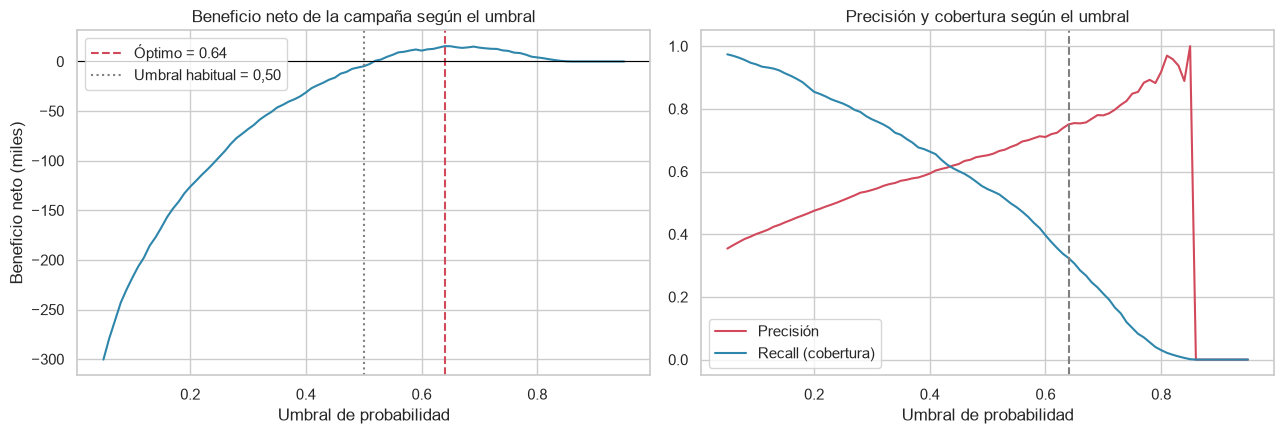

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(curva["umbral"], curva["beneficio"] / 1000, color="#2e86ab")
axes[0].axvline(mejor["umbral"], color="#d1495b", linestyle="--", label=f"Óptimo = {mejor['umbral']:.2f}")
axes[0].axvline(0.5, color="gray", linestyle=":", label="Umbral habitual = 0,50")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Beneficio neto de la campaña según el umbral")
axes[0].set_xlabel("Umbral de probabilidad")
axes[0].set_ylabel("Beneficio neto (miles)")
axes[0].legend()

axes[1].plot(curva["umbral"], curva["precision"], label="Precisión", color="#d1495b")
axes[1].plot(curva["umbral"], curva["recall"], label="Recall (cobertura)", color="#2e86ab")
axes[1].axvline(mejor["umbral"], color="gray", linestyle="--")
axes[1].set_title("Precisión y cobertura según el umbral")
axes[1].set_xlabel("Umbral de probabilidad")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURAS / "07_umbral_beneficio.png", dpi=150)
plt.show()

## 4. Resultado en el grupo de prueba

Aplicamos el umbral elegido al grupo que el modelo nunca vio y lo comparamos con tres alternativas: no hacer nada, contactar a todos, y usar el umbral habitual de 0,50.

In [6]:
mensual_test = X_test["MonthlyCharges"].to_numpy()
y_test_np = y_test.to_numpy()
u_opt = float(mejor["umbral"])

estrategias = {
    "No hacer nada": np.zeros(len(y_test_np), dtype=bool),
    "Contactar a todos": np.ones(len(y_test_np), dtype=bool),
    "Umbral 0,50": p_test >= 0.5,
    f"Umbral óptimo ({u_opt:.2f})": p_test >= u_opt,
}

filas = []
for nombre, contactado in estrategias.items():
    filas.append({
        "estrategia": nombre,
        "contactados": int(contactado.sum()),
        "fugas_alcanzadas": int((contactado & (y_test_np == 1)).sum()),
        "beneficio_neto": round(beneficio_neto(y_test_np, mensual_test, contactado)),
    })

comparacion = pd.DataFrame(filas).set_index("estrategia")
print("Fugas reales en el grupo de prueba:", int(y_test_np.sum()))
comparacion

Fugas reales en el grupo de prueba: 374


,contactados,fugas_alcanzadas,beneficio_neto
estrategia,,,
No hacer nada,0,0,0
Contactar a todos,1409,374,-118749
"Umbral 0,50",318,209,-1337
Umbral óptimo (0.64),161,121,3681


## 5. ¿Y si los supuestos cambian?

Los supuestos son una hipótesis. Veamos cómo cambian el umbral óptimo y el beneficio al variar el éxito de la oferta y su costo. Cada combinación se evalúa con el mismo procedimiento: se elige el umbral en entrenamiento y se mide en prueba.

In [7]:
filas = []
for exito in [0.2, 0.3, 0.5]:
    for descuento in [0.1, 0.2, 0.3]:
        beneficios = [beneficio_neto(y_train_np, mensual_train, p_train >= u, exito, descuento) for u in umbrales]
        u = float(umbrales[int(np.argmax(beneficios))])
        filas.append({
            "éxito de la oferta": exito,
            "costo (descuento)": descuento,
            "umbral óptimo": u,
            "beneficio en prueba": round(beneficio_neto(y_test_np, mensual_test, p_test >= u, exito, descuento)),
        })

sensibilidad = pd.DataFrame(filas)
sensibilidad.pivot(index="éxito de la oferta", columns="costo (descuento)", values="beneficio en prueba")

costo (descuento),0.1,0.2,0.3
éxito de la oferta,,,
0.2,8469,0,0
0.3,27893,3681,0
0.5,83121,33735,10623


In [8]:
sensibilidad.pivot(index="éxito de la oferta", columns="costo (descuento)", values="umbral óptimo")

costo (descuento),0.1,0.2,0.3
éxito de la oferta,,,
0.2,0.56,0.85,0.86
0.3,0.35,0.64,0.85
0.5,0.17,0.41,0.59


## 6. ¿A quién llamar primero? Ranking por riesgo

Ordenamos a los clientes del grupo de prueba de mayor a menor riesgo y los dividimos en 10 grupos de igual tamaño (deciles). Si el modelo sirve, los primeros deciles concentran la mayoría de las fugas.

       clientes  fugas  tasa_churn  fugas_acumuladas_%
decil                                                 
1           141    105       0.745                28.1
2           141     81       0.574                49.7
3           141     57       0.404                65.0
4           141     49       0.348                78.1
5           141     34       0.241                87.2
6           140     23       0.164                93.3
7           141     16       0.113                97.6
8           141      5       0.035                98.9
9           141      2       0.014                99.5
10          141      2       0.014               100.0


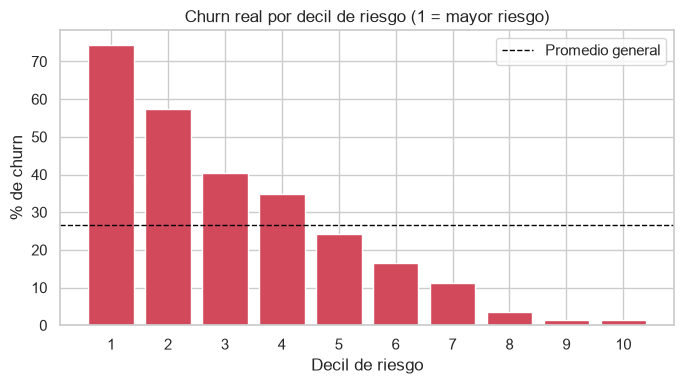

In [9]:
orden = pd.DataFrame({"y": y_test_np, "p": p_test}).sort_values("p", ascending=False).reset_index(drop=True)
orden["decil"] = pd.qcut(orden.index, 10, labels=range(1, 11))

deciles = orden.groupby("decil", observed=True).agg(clientes=("y", "size"), fugas=("y", "sum"), tasa_churn=("y", "mean"))
deciles["fugas_acumuladas_%"] = (deciles["fugas"].cumsum() / deciles["fugas"].sum() * 100).round(1)
deciles["tasa_churn"] = deciles["tasa_churn"].round(3)
print(deciles)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(deciles.index.astype(str), deciles["tasa_churn"] * 100, color="#d1495b")
ax.axhline(y_test_np.mean() * 100, color="black", linestyle="--", linewidth=1, label="Promedio general")
ax.set_title("Churn real por decil de riesgo (1 = mayor riesgo)")
ax.set_xlabel("Decil de riesgo")
ax.set_ylabel("% de churn")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURAS / "08_churn_por_decil.png", dpi=150)
plt.show()

## 7. Conclusiones del paso 4

*Completa con tus palabras:*

1. ¿Qué umbral resultó óptimo y en qué se diferencia del 0,50 habitual?
 Con los supuestos base (la oferta cuesta un 20 % de los ingresos de 12 meses y retiene al 30 % de quienes se iban), el umbral óptimo es 0,64, bastante más alto que el 0,50 habitual. Solo conviene ofrecer descuento a clientes con alta probabilidad de fuga, porque a quien no se iba la oferta le cuesta dinero igual. 
2. ¿Cuánto beneficio agrega frente a "no hacer nada" y a "contactar a todos"? 
 La campaña con ese umbral deja un beneficio neto de 3.681 en el grupo de prueba, frente a 0 de no hacer nada. 
3. ¿Qué pasa si la oferta funciona peor o cuesta más?
 El resultado depende mucho de los supuestos. Si la oferta retiene solo al 20 % o cuesta un 30 %, el beneficio cae a 0 y lo mejor es no hacer nada. Si retiene al 50 % y cuesta un 10 %, el umbral óptimo baja a 0,17 y el beneficio sube a 83.121. Cuanto más barata y eficaz es la oferta, a más clientes conviene llegar. El supuesto decisivo es la tasa de éxito de la oferta, y los datos no permiten estimarla. 
4. ¿Qué porcentaje de las fugas concentra el 20 % de clientes de mayor riesgo? 
 Los clientes del decil 1 (el 10 % de mayor riesgo) se fueron en un 74,5 %, frente a un promedio de 26,5 %. El 20 % de mayor riesgo concentra el 49,7 % de las fugas, y el 40 % concentra el 78,1 %. El modelo ordena bien a los clientes: priorizar por riesgo es mucho más eficiente que contactar al azar.